# 04c. Análisis estadístico y exploratorio INEGI-ATUS — Avance 03

**Proyecto:** Análisis de hechos de tránsito en la Ciudad de México  
**Equipo:** A&C — Méndez Cabral Ángel David (`23-003-1466`) y Ruiz Moreno Citlalli Viviana (`23-003-1162`) · UACM · Inteligencia de Negocios · Grupo 301 · 2026-2

## Objetivo
Calcular e interpretar 4 medidas/bloques estadísticos descriptivos pertinentes (`idn_avance03_guia.pdf`, sección 3.5) exclusivamente sobre las salidas limpias y de auditoría generadas por `03_ETL_INEGI_ATUS_Avance03 .ipynb` (`2018–2025`), manteniendo la **no integración explícita** (`§3.2`, `§10`) respecto a SSC y C5.

> **Advertencia de unidad de observación:** En INEGI-ATUS cada registro corresponde a **1 accidente administrativo registrado en las 46 columnas oficiales**, donde `_total_heridos_validado` (`17,637` personas heridas) y `_total_fallecidos_validado` (`1,896` fallecidos de contexto) provienen de estadística anual consolidada y no deben sumarse con los conteos de SSC ni reportes C5.

**Matriz estadística planificada (Nota 10 / Guía §3.5):**
1. **Territorial (Alcaldía):** suma y `%` de `_total_heridos_validado`, accidentes y fallecidos por `alcaldia_normalizada` (`16` demarcaciones).
2. **Temporal (Franja horaria `ID_HORA`):** suma y `%` de `_total_heridos_validado`, accidentes y fallecidos por `_franja_horaria` (`Madrugada`, `Mañana`, `Tarde`, `Noche`), con `0` horas faltantes y contraste entre concentración diurna de heridos y pico nocturno/madrugada de fallecidos.
3. **Severidad por accidente y clase (`CLASACC`):** media, mediana, moda, desviación estándar, cuartiles (`Q1, Q2, Q3`), mínimo y máximo de `_total_heridos_validado` por accidente (`N = 62,277`), junto al desglose entre *Sólo daños*, *No fatal* y *Fatal*.
4. **Impacto de `INEGI-R01` (pre/post `145` duplicados), evolución anual y edad del conductor (`ID_EDAD`):** comparativa antes vs. después de retirar los `145` duplicados exactos sobre las 46 columnas (`62,424` → `62,277` limpios + `2` pendientes `2023-12-32`), serie anual `2018–2025` y perfil etario conocido (`1–98`, separando explícitamente `0 = Se fugó` y `99 = No especificado`).

## 1. Entorno, selección automática de la corrida limpia de INEGI-ATUS y bitácora
Busca la ejecución completa más reciente en `data/processed/INEGI_ATUS/<RUN_ID>/` (`INEGI_ATUS_limpio.csv.gz`, `_duplicados_exactos.csv.gz`, `_pendientes.csv.gz`). Configura la exportación estadística en `data/processed/Analisis_INEGI_ATUS/<RUN_ID>/` y sincroniza el paso resumen en `bitacora/bitacora.csv`.

In [1]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import csv
import gzip
import io
import re
import unicodedata
import numpy as np
import pandas as pd
from IPython.display import display, Image as IPyImage

try:
    import matplotlib.pyplot as plt
except ImportError:
    plt = None

try:
    from PIL import Image as PilImage, ImageDraw, ImageFont
except ImportError:
    PilImage = None

TZ = ZoneInfo("America/Mexico_City")
RESPONSABLE_EQUIPO = "Equipo A&C (Méndez Cabral Ángel David; Ruiz Moreno Citlalli Viviana)"
VERSION_PROCESO = "Avance03-v4"

def localizar_raiz_avance03():
    actual = Path.cwd().resolve()
    for carpeta in [actual, *actual.parents]:
        if (carpeta / "04c_Analisis_Estadistico_INEGI_ATUS_Avance03 .ipynb").is_file() or (carpeta / "04_Analisis_Estadistico_Avance03 .ipynb").is_file() or carpeta.name.lower() == "avance03":
            return carpeta
        if (carpeta / "data" / "processed" / "INEGI_ATUS").is_dir():
            return carpeta
    return actual

ROOT = localizar_raiz_avance03()
ATUS_OUT = ROOT / "data" / "processed" / "INEGI_ATUS"
ANALISIS_ROOT = ROOT / "data" / "processed" / "Analisis_INEGI_ATUS"
LOG_DIR = ROOT / "bitacora" / "Analisis_INEGI_ATUS"
BITACORA_GLOBAL_PATH = ROOT / "bitacora" / "bitacora.csv"

RUN_ID = datetime.now(TZ).strftime("%Y%m%d_%H%M%S")
RUN = ANALISIS_ROOT / RUN_ID
RUN_LOG = LOG_DIR / RUN_ID
RUN.mkdir(parents=True, exist_ok=True)
RUN_LOG.mkdir(parents=True, exist_ok=True)

candidatos_run = []
if ATUS_OUT.is_dir():
    runs = sorted(
        [p for p in ATUS_OUT.iterdir() if p.is_dir() and not p.name.startswith(".")],
        key=lambda p: p.name,
        reverse=True,
    )
    for carpeta in runs:
        limpios = sorted(list(carpeta.glob("*_limpio.csv.gz")) + list(carpeta.glob("*_limpio.csv")))
        dups = sorted(list(carpeta.glob("*_duplicados_exactos.csv.gz")) + list(carpeta.glob("*_duplicados_exactos.csv")))
        pends = sorted(list(carpeta.glob("*_pendientes.csv.gz")) + list(carpeta.glob("*_pendientes.csv")))
        if limpios:
            candidatos_run.append((carpeta, limpios[0], dups[0] if dups else None, pends[0] if pends else None))

if not candidatos_run:
    raise FileNotFoundError(
        f"No se encontró ninguna corrida completa de 03_ETL_INEGI_ATUS en {ATUS_OUT}. "
        "Ejecuta primero 03_ETL_INEGI_ATUS_Avance03 .ipynb."
    )

ATUS_RUN, ARCH_LIMPIO, ARCH_DUPS, ARCH_PEND = candidatos_run[0]
ORIGEN_ATUS = "Avance03 - ETL INEGI-ATUS (limpios .csv.gz)"

print("Origen de datos INEGI-ATUS:", ORIGEN_ATUS)
print("Carpeta INEGI-ATUS seleccionada:", ATUS_RUN)
print(" - Limpio:", ARCH_LIMPIO.name, f"({ARCH_LIMPIO.stat().st_size / 1024:.1f} KB)")
if ARCH_DUPS is not None:
    print(" - Duplicados exactos:", ARCH_DUPS.name, f"({ARCH_DUPS.stat().st_size / 1024:.1f} KB)")
if ARCH_PEND is not None:
    print(" - Pendientes calendario:", ARCH_PEND.name, f"({ARCH_PEND.stat().st_size / 1024:.1f} KB)")
print("Carpeta de salida del análisis INEGI-ATUS:", RUN)
print("Matplotlib disponible:", plt is not None)

Origen de datos INEGI-ATUS: Avance03 - ETL INEGI-ATUS (limpios .csv.gz)
Carpeta INEGI-ATUS seleccionada: C:\Users\angel\Downloads\CARPETA_DATOS\data\processed\INEGI_ATUS\20261109_043449
 - Limpio: INEGI_ATUS_limpio.csv.gz (994.6 KB)
 - Duplicados exactos: INEGI_ATUS_duplicados_exactos.csv.gz (2.9 KB)
 - Pendientes calendario: INEGI_ATUS_pendientes.csv.gz (0.7 KB)
Carpeta de salida del análisis INEGI-ATUS: C:\Users\angel\Downloads\CARPETA_DATOS\data\processed\Analisis_INEGI_ATUS\20261109_132940
Matplotlib disponible: False


## 2. Lectura y funciones auxiliares de visualización
Leemos el conjunto limpio (`INEGI_ATUS_limpio.csv.gz`) junto con los duplicados retirados (`INEGI-R01`) y pendientes calendáricos (`INEGI-R02`) para documentar el impacto metodológico completo sin integrar con SSC o C5 (`§10`).

In [2]:
def nrm(valor):
    t = unicodedata.normalize("NFKD", str(valor)).encode("ascii", "ignore").decode("ascii").lower()
    return re.sub(r"[^a-z0-9]+", "_", t).strip("_")

def findcol(df, aliases):
    mapa = {nrm(col): col for col in df.columns}
    for alias in aliases:
        if nrm(alias) in mapa:
            return mapa[nrm(alias)]
    return None

def leer_resultado(path):
    return pd.read_csv(path, dtype="string", encoding="utf-8-sig", compression="infer", low_memory=False)

def guardar_resumen(df, nombre):
    destino = RUN / nombre
    df.to_csv(destino, index=False, encoding="utf-8-sig", compression="gzip")
    return destino

def _ui_font(size, bold=False):
    rutas = (
        [r"C:\Windows\Fonts\segoeuib.ttf", r"C:\Windows\Fonts\calibrib.ttf", r"C:\Windows\Fonts\arialbd.ttf", "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf"]
        if bold else
        [r"C:\Windows\Fonts\segoeui.ttf", r"C:\Windows\Fonts\calibri.ttf", r"C:\Windows\Fonts\arial.ttf", "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf"]
    )
    for r in rutas:
        if Path(r).is_file():
            return ImageFont.truetype(r, size=size)
    return ImageFont.load_default()

def _mostrar_y_guardar_pil(img, nombre_png):
    out_png = RUN / nombre_png
    img.save(out_png, dpi=(180, 180))
    buf = io.BytesIO()
    img.save(buf, format="PNG")
    display(IPyImage(data=buf.getvalue()))
    return out_png

def graficar_barh_alcaldia_inegi_pil(df_alc, total_her, total_acc, total_fal):
    NAVY, AMBER, BLUE, SLATE, MUTED, GRID = (15, 39, 68), (217, 119, 6), (30, 64, 120), (71, 85, 105), (100, 116, 139), (226, 232, 240)
    W, H = 1200, 720
    img = PilImage.new("RGB", (W, H), (255, 255, 255))
    d = ImageDraw.Draw(img)
    f_t, f_s, f_l, f_v, f_ax = _ui_font(26, True), _ui_font(15), _ui_font(15, True), _ui_font(14), _ui_font(13)
    d.text((45, 22), "Personas heridas por alcaldía — INEGI-ATUS (2018–2025)", fill=NAVY, font=f_t)
    d.text((45, 56), f"Total limpio: {total_her:,} heridos y {total_fal:,} fallecidos (contexto) en {total_acc:,} accidentes · Variable: alcaldia_normalizada", fill=MUTED, font=f_s)
    lx, rx, ty, rh, bh = 270, 960, 104, 34, 23
    max_v = 4000
    for tk in range(0, max_v + 1, 1000):
        x = int(lx + (tk / max_v) * (rx - lx))
        d.line([(x, ty - 6), (x, ty + 16 * rh - 6)], fill=GRID, width=1)
        d.text((x - 16, ty + 16 * rh + 2), f"{tk:,}", fill=MUTED, font=f_ax)
    for i, row in df_alc.iterrows():
        y0 = ty + i * rh
        val, pct, acc = int(row["heridos"]), float(row["porcentaje_heridos"]), int(row["accidentes"])
        bw = max(3, int((val / max_v) * (rx - lx)))
        name = str(row["alcaldia"])
        tw = d.textlength(name, font=f_l)
        d.text((lx - 14 - tw, y0 + 2), name, fill=NAVY if i < 3 else SLATE, font=f_l)
        d.rounded_rectangle([lx, y0, lx + bw, y0 + bh], radius=4, fill=AMBER if i < 3 else BLUE)
        d.text((lx + bw + 10, y0 + 2), f"{val:,} ({pct:.2f}% · {acc:,} acc.)", fill=NAVY if i < 3 else SLATE, font=f_v)
    top3_pct = float(df_alc.head(3)["porcentaje_heridos"].sum())
    d.text((45, 686), f"Top 3 en naranja (Cuauhtémoc, Gustavo A. Madero e Iztapalapa = {top3_pct:.2f}% de los heridos ATUS). Fuente estadística anual independiente.", fill=MUTED, font=f_ax)
    return _mostrar_y_guardar_pil(img, "grafica_01_alcaldias_inegi.png")

def graficar_bar_franjas_inegi_pil(df_fr, total_her, total_fal):
    NAVY, TEAL, BLUE, CORAL, SLATE, MUTED, GRID = (15, 39, 68), (13, 148, 136), (30, 64, 120), (220, 38, 38), (71, 85, 105), (100, 116, 139), (226, 232, 240)
    W, H = 1080, 610
    img = PilImage.new("RGB", (W, H), (255, 255, 255))
    d = ImageDraw.Draw(img)
    f_t, f_s, f_l, f_b, f_ax = _ui_font(24, True), _ui_font(15), _ui_font(16, True), _ui_font(19, True), _ui_font(13)
    d.text((45, 22), "Personas heridas y fallecidas por franja horaria — INEGI-ATUS (ID_HORA)", fill=NAVY, font=f_t)
    d.text((45, 55), f"Cobertura horaria 100% completa (0 sin hora válida): {total_her:,} heridos y {total_fal:,} fallecidos (contexto)", fill=MUTED, font=f_s)
    px0, px1, py0, py1, max_f = 110, 1010, 128, 455, 6000
    for tk in range(0, max_f + 1, 1000):
        y = int(py1 - (tk / max_f) * (py1 - py0))
        d.line([(px0, y), (px1, y)], fill=GRID, width=1)
        tw = d.textlength(f"{tk:,}", font=f_ax)
        d.text((px0 - 12 - tw, y - 8), f"{tk:,}", fill=MUTED, font=f_ax)
    bw = 135
    gap = (px1 - px0 - 4 * bw) // 5
    max_val = int(df_fr["heridos"].max())
    hrs = {"Madrugada": "00:00–05:59", "Mañana": "06:00–11:59", "Tarde": "12:00–17:59", "Noche": "18:00–23:59"}
    for i, r in df_fr.iterrows():
        fr, val, fal, acc = str(r["franja"]), int(r["heridos"]), int(r["fallecidos"]), int(r["accidentes"])
        bx0 = px0 + gap * (i + 1) + bw * i
        bx1 = bx0 + bw
        bh = int((val / max_f) * (py1 - py0))
        by0 = py1 - bh
        col = TEAL if val == max_val else BLUE
        d.rounded_rectangle([bx0, by0, bx1, py1], radius=6, fill=col)
        vs = f"{val:,}"
        d.text((bx0 + (bw - d.textlength(vs, font=f_b)) / 2, by0 - 46), vs, fill=NAVY, font=f_b)
        ps = f"{r['porcentaje_heridos']:.1f}% ({acc:,} acc.)"
        d.text((bx0 + (bw - d.textlength(ps, font=f_ax)) / 2, by0 - 22), ps, fill=TEAL if val == max_val else MUTED, font=f_ax)
        d.text((bx0 + (bw - d.textlength(fr, font=f_l)) / 2, py1 + 10), fr, fill=NAVY, font=f_l)
        hs = hrs.get(fr, "")
        d.text((bx0 + (bw - d.textlength(hs, font=f_ax)) / 2, py1 + 32), hs, fill=MUTED, font=f_ax)
        fs = f"{fal:,} fallecidos"
        d.text((bx0 + (bw - d.textlength(fs, font=_ui_font(12, True))) / 2, py1 + 52), fs, fill=CORAL if fal >= 490 else SLATE, font=_ui_font(12, True))
    r_tar = df_fr.loc[df_fr["franja"] == "Tarde"].iloc[0]
    r_man = df_fr.loc[df_fr["franja"] == "Mañana"].iloc[0]
    r_mad = df_fr.loc[df_fr["franja"] == "Madrugada"].iloc[0]
    d.rounded_rectangle([45, 542, 1035, 588], radius=6, fill=(254, 243, 199), outline=(217, 119, 6), width=1)
    d.text((60, 550), f"Contraste de severidad: Tarde concentra más heridos ({int(r_tar['heridos']):,} = {r_tar['porcentaje_heridos']:.2f}%) y Mañana más fallecidos ({int(r_man['fallecidos']):,}),", fill=(120, 53, 15), font=f_ax)
    d.text((60, 567), f"pero Madrugada registra la mayor letalidad relativa: {r_mad['fallecidos_por_100_acc']:.2f} fallecidos por cada 100 acc. ({int(r_mad['fallecidos']):,} en {int(r_mad['accidentes']):,}).", fill=(120, 53, 15), font=f_ax)
    return _mostrar_y_guardar_pil(img, "grafica_02_franjas_inegi.png")

def graficar_boxplot_heridos_inegi_pil(serie_her, df_clasacc):
    NAVY, TEAL, AMBER, CORAL, SLATE, MUTED, GRID = (15, 39, 68), (13, 148, 136), (217, 119, 6), (220, 38, 38), (71, 85, 105), (100, 116, 139), (226, 232, 240)
    W, H = 1080, 540
    img = PilImage.new("RGB", (W, H), (255, 255, 255))
    d = ImageDraw.Draw(img)
    f_t, f_s, f_b, f_ax = _ui_font(24, True), _ui_font(15), _ui_font(17, True), _ui_font(13)
    q1, q2, q3 = float(serie_her.quantile(.25)), float(serie_her.median()), float(serie_her.quantile(.75))
    med, desv, vmin, vmax = float(serie_her.mean()), float(serie_her.std()), float(serie_her.min()), float(serie_her.max())
    d.text((45, 22), "Caja y bigotes — heridos por accidente y clase CLASACC (INEGI-ATUS)", fill=NAVY, font=f_t)
    d.text((45, 54), f"N = {len(serie_her):,} accidentes · 77.19% con 0 heridos (Q1=Q2=Q3=0) y cola derecha atípica hasta {int(vmax)}", fill=MUTED, font=f_s)
    px0, px1, py0, py1, y_max = 105, 525, 110, 465, max(45.0, vmax + 2.0)
    y_of = lambda v: int(py1 - (v / y_max) * (py1 - py0))
    for tk in range(0, 46, 5):
        y = y_of(tk)
        d.line([(px0, y), (px1, y)], fill=GRID, width=1)
        tw = d.textlength(str(tk), font=f_ax)
        d.text((px0 - 12 - tw, y - 8), str(tk), fill=MUTED, font=f_ax)
    d.line([(px0, py0), (px0, py1), (px1, py1)], fill=SLATE, width=2)
    cx = 245
    bx_l, bx_r = cx - 55, cx + 55
    y0_box = y_of(0)
    d.rectangle([bx_l, y0_box - 5, bx_r, y0_box + 5], fill=(204, 251, 241), outline=TEAL, width=2)
    d.line([(bx_l, y0_box), (bx_r, y0_box)], fill=AMBER, width=4)
    ym = y_of(med)
    d.polygon([(cx, ym - 6), (cx - 7, ym + 6), (cx + 7, ym + 6)], fill=AMBER, outline=NAVY)
    for ov in sorted(set(int(v) for v in serie_her.unique() if v > 0)):
        yo = y_of(ov)
        d.ellipse([cx - 4, yo - 4, cx + 4, yo + 4], outline=CORAL, fill=(254, 226, 226), width=2)
    d.text((bx_r + 12, y0_box - 17), "Q1 = Q2 = Q3 = 0.0 (77.19%)", fill=TEAL, font=_ui_font(12, True))
    d.line([(cx + 8, ym), (bx_r + 10, y0_box - 38)], fill=NAVY, width=1)
    d.text((bx_r + 12, y0_box - 46), f"Media = {med:.4f} (triángulo)", fill=NAVY, font=_ui_font(12, True))
    d.text((cx + 16, y_of(vmax) - 8), f"Máx = {int(vmax)} heridos", fill=CORAL, font=_ui_font(12, True))
    xlbl = "_total_heridos_validado (ATUS)"
    d.text((cx - d.textlength(xlbl, font=f_ax) / 2, py1 + 14), xlbl, fill=NAVY, font=f_ax)

    # Right summary card (stats + CLASACC breakdown)
    d.rounded_rectangle([555, 108, 1035, 488], radius=10, fill=(248, 250, 252), outline=GRID, width=2)
    d.text((580, 126), "Severidad y desglose CLASACC", fill=NAVY, font=f_b)
    d.line([(580, 154), (1010, 154)], fill=GRID, width=1)
    items = [
        ("Media / Mediana / Moda:", f"{med:.4f}  |  Mediana = {q2:.1f}  |  Moda = {int(serie_her.mode().iloc[0])}"),
        ("Desv. estándar y rango:", f"DE = {desv:.4f}  |  Rango = {int(vmin)} a {int(vmax)} heridos"),
        ("Ceros vs. >= 1 herido:", f"{int((serie_her==0).sum()):,} con 0 ({(serie_her==0).mean()*100:.2f}%) vs. {int((serie_her>0).sum()):,} con >=1"),
    ]
    cy = 168
    for k, v in items:
        d.text((580, cy), k, fill=MUTED, font=f_ax)
        d.text((580, cy + 17), v, fill=NAVY, font=_ui_font(14, True))
        cy += 44
    d.line([(580, 306), (1010, 306)], fill=GRID, width=1)
    d.text((580, 318), "Distribución por CLASACC (62,277 accidentes)", fill=NAVY, font=_ui_font(14, True))
    cy = 346
    cls_cols = {"Sólo daños": SLATE, "No fatal": TEAL, "Fatal": CORAL}
    for _, rc in df_clasacc.iterrows():
        cls_name = str(rc["CLASACC"])
        acc_c, her_c, fal_c, pct_c = int(rc["accidentes"]), int(rc["heridos"]), int(rc["fallecidos"]), float(rc["porcentaje_accidentes"])
        c_bar = cls_cols.get(cls_name, SLATE)
        d.text((580, cy), f"{cls_name}: {acc_c:,} ({pct_c:.2f}%)", fill=NAVY, font=_ui_font(13, True))
        d.text((805, cy), f"{her_c:,} her. · {fal_c:,} fall.", fill=c_bar, font=f_ax)
        bw = max(4, int((pct_c / 100.0) * 425))
        d.rounded_rectangle([580, cy + 20, 580 + bw, cy + 32], radius=3, fill=c_bar)
        cy += 45
    return _mostrar_y_guardar_pil(img, "grafica_03_boxplot_heridos_inegi.png")

def graficar_comparativa_r01_y_anual_inegi_pil(df_anual, df_comp_r01, ed_stats):
    NAVY, TEAL, AMBER, CORAL, BLUE, SLATE, MUTED, GRID = (15, 39, 68), (13, 148, 136), (217, 119, 6), (220, 38, 38), (30, 64, 120), (71, 85, 105), (100, 116, 139), (226, 232, 240)
    W, H = 1240, 620
    img = PilImage.new("RGB", (W, H), (255, 255, 255))
    d = ImageDraw.Draw(img)
    f_t, f_s, f_b, f_ax = _ui_font(24, True), _ui_font(15), _ui_font(16, True), _ui_font(12)
    d.text((40, 20), "Serie anual (2018–2025), impacto INEGI-R01 y edad del conductor — ATUS", fill=NAVY, font=f_t)
    d.text((40, 52), "Comparativa directa tras retirar 145 duplicados exactos sobre 46 cols (1 en fecha inválida 2023-12-32) + perfil ID_EDAD", fill=MUTED, font=f_s)

    # Left panel: Annual accidents & heridos 2018-2025
    d.rounded_rectangle([40, 95, 745, 555], radius=10, fill=(248, 250, 252), outline=GRID, width=1)
    d.text((58, 112), "Evolución anual CDMX limpia: Accidentes vs. Heridos (2018–2025)", fill=NAVY, font=f_b)
    px0, px1, py0, py1, max_a = 115, 715, 175, 485, 13000
    for tk in range(0, 12001, 3000):
        y = int(py1 - (tk / max_a) * (py1 - py0))
        d.line([(px0, y), (px1, y)], fill=GRID, width=1)
        tw = d.textlength(f"{tk:,}", font=f_ax)
        d.text((px0 - 8 - tw, y - 7), f"{tk:,}", fill=MUTED, font=f_ax)
    n_yr = len(df_anual)
    slot = (px1 - px0) // n_yr
    for i, r in df_anual.iterrows():
        yr = str(r["ANIO"])
        acc = int(r["accidentes"])
        her = int(r["heridos"])
        x_mid = px0 + slot * i + slot // 2
        # Blue bar = accidentes, Teal bar beside = heridos
        bh1 = int((acc / max_a) * (py1 - py0))
        bh2 = int((her / max_a) * (py1 - py0))
        d.rounded_rectangle([x_mid - 24, py1 - bh1, x_mid - 2, py1], radius=3, fill=BLUE)
        d.rounded_rectangle([x_mid + 2, py1 - bh2, x_mid + 24, py1], radius=3, fill=TEAL)
        d.text((x_mid - 24, py1 - bh1 - 16), f"{acc:,}", fill=NAVY, font=_ui_font(10, True))
        d.text((x_mid + 2, py1 - bh2 - 16), f"{her:,}", fill=TEAL, font=_ui_font(10, True))
        yw = d.textlength(yr, font=_ui_font(12, True))
        d.text((x_mid - yw / 2, py1 + 8), yr, fill=NAVY, font=_ui_font(12, True))
    d.rectangle([60, 518, 76, 532], fill=BLUE); d.text((82, 518), "Accidentes limpios (total 62,277)", fill=NAVY, font=f_ax)
    d.rectangle([310, 518, 326, 532], fill=TEAL); d.text((332, 518), "Personas heridas (total 17,637)", fill=TEAL, font=f_ax)

    # Right panel: INEGI-R01 pre/post + ID_EDAD summary
    d.rounded_rectangle([765, 95, 1200, 555], radius=10, fill=(248, 250, 252), outline=GRID, width=1)
    d.text((785, 112), "Impacto de INEGI-R01 y perfil ID_EDAD", fill=NAVY, font=f_b)
    d.line([(785, 142), (1180, 142)], fill=GRID, width=1)
    r_pre = df_comp_r01.iloc[0]
    r_post = df_comp_r01.iloc[1]
    cards = [
        ("Delimitado pre INEGI-R01:", f"{int(r_pre['accidentes']):,} acc. · {int(r_pre['heridos']):,} heridos", SLATE),
        ("Limpio post INEGI-R01 (+2 pend.):", f"{int(r_post['accidentes']):,} acc. · {int(r_post['heridos']):,} heridos", TEAL),
        ("Copias exactas retiradas (46 cols):", "145 filas (-15 heridos; 1 en 2023-12-32)", CORAL),
        ("Concentración de duplicados:", "Cuauhtémoc 75/145 (51.7%) · 2024: 77/145", AMBER),
        ("Edad conocida conductor (1–98):", f"N={ed_stats['n_ok']:,} · Media={ed_stats['mean']:.2f} · Mediana={int(ed_stats['median'])} · Moda={int(ed_stats['mode'])}", NAVY),
        ("Cuartiles Q1–Q3 / DE conductor:", f"Q1={int(ed_stats['q1'])} – Q3={int(ed_stats['q3'])} años (DE={ed_stats['std']:.2f})", NAVY),
        ("Códigos especiales separados (RG-03):", f"0 = Se fugó: {ed_stats['n_fugo']:,} · 99 = N/E: {ed_stats['n_99']:,}", MUTED),
    ]
    cy = 156
    for k, v, col in cards:
        d.text((785, cy), k, fill=MUTED, font=f_ax)
        d.text((785, cy + 16), v, fill=col, font=_ui_font(13, True))
        cy += 55

    d.rounded_rectangle([40, 568, 1200, 604], radius=6, fill=(254, 243, 199), outline=AMBER, width=1)
    d.text((56, 579), "Criterio RG-03 / INEGI-R02: 12,948 registros con ID_EDAD=0 coinciden 100% con SEXO='Se fugó'; las 2 fechas únicas 2023-12-32 permanecen en pendientes sin suposición.", fill=(120, 53, 15), font=f_ax)
    return _mostrar_y_guardar_pil(img, "grafica_04_comparativa_r01_y_anual_inegi.png")

atus_limpio = leer_resultado(ARCH_LIMPIO)
atus_dups = leer_resultado(ARCH_DUPS) if ARCH_DUPS is not None else pd.DataFrame()
atus_pend = leer_resultado(ARCH_PEND) if ARCH_PEND is not None else pd.DataFrame()
print(f"Leído limpio: {ARCH_LIMPIO.name} | {len(atus_limpio):,} filas x {len(atus_limpio.columns)} cols")
print(f"Duplicados exactos: {len(atus_dups):,} | Pendientes calendario: {len(atus_pend):,}")

Leído limpio: INEGI_ATUS_limpio.csv.gz | 62,277 filas x 58 cols
Duplicados exactos: 145 | Pendientes calendario: 2


## 3. Identificación de variables clave en INEGI-ATUS
Verificamos las variables normalizadas y validadas por `03_ETL_INEGI_ATUS_Avance03`: `alcaldia_normalizada`, `_total_heridos_validado`, `_total_fallecidos_validado`, `_franja_horaria`, `ANIO`, `CLASACC`, `ID_EDAD` y `SEXO`.

In [3]:
COL_ALC = findcol(atus_limpio, ["alcaldia_normalizada"])
COL_HER = findcol(atus_limpio, ["_total_heridos_validado"])
COL_FAL = findcol(atus_limpio, ["_total_fallecidos_validado"])
COL_FRANJA = findcol(atus_limpio, ["_franja_horaria"])
COL_ANIO = findcol(atus_limpio, ["ANIO"])
COL_CLAS = findcol(atus_limpio, ["CLASACC"])
COL_EDAD = findcol(atus_limpio, ["ID_EDAD"])
COL_SEXO = findcol(atus_limpio, ["SEXO"])

assert COL_ALC and COL_HER and COL_FAL and COL_FRANJA and COL_ANIO and COL_CLAS
print("Tabla limpia:", ARCH_LIMPIO.name, "| Dimensiones:", atus_limpio.shape)
print({
    "alcaldia": COL_ALC,
    "heridos": COL_HER,
    "fallecidos_contexto": COL_FAL,
    "franja_horaria": COL_FRANJA,
    "anio": COL_ANIO,
    "clasacc": COL_CLAS,
    "edad_conductor": COL_EDAD,
})

Tabla limpia: INEGI_ATUS_limpio.csv.gz | Dimensiones: (62277, 58)
{'alcaldia': 'alcaldia_normalizada', 'heridos': '_total_heridos_validado', 'fallecidos_contexto': '_total_fallecidos_validado', 'franja_horaria': '_franja_horaria', 'anio': 'ANIO', 'clasacc': 'CLASACC', 'edad_conductor': 'ID_EDAD'}


## 4. Medida 1 — Distribución territorial de personas heridas y accidentes por alcaldía (`alcaldia_normalizada`)
- **Pregunta analítica:** ¿En qué alcaldías se concentra el mayor volumen de personas heridas registradas en la estadística oficial INEGI-ATUS (`2018–2025`)?
- **Variables y medida:** `_total_heridos_validado`, `_total_fallecidos_validado` y conteo de accidentes agrupados por `alcaldia_normalizada` · **Suma total y `%` de participación**.
- **Justificación:** Permite contrastar la distribución territorial oficial del INEGI frente a SSC (fuente principal) manteniendo cuentas separadas.

Total limpio INEGI-ATUS (16 alcaldías): 17,637 heridos y 1,896 fallecidos en 62,277 accidentes.
Top 3 concentran: 8,054 heridos (45.67%).


,alcaldia,accidentes,heridos,fallecidos,porcentaje_heridos,porcentaje_accidentes
0,Cuauhtémoc,9110,3359,222,19.05,14.63
1,Gustavo A. Madero,8092,2961,339,16.79,12.99
2,Iztapalapa,6868,1734,214,9.83,11.03
3,Venustiano Carranza,4099,1516,138,8.60,6.58
4,Álvaro Obregón,4789,1475,168,8.36,7.69
5,Tlalpan,4132,1067,157,6.05,6.63
6,Benito Juárez,4827,1043,98,5.91,7.75
7,Iztacalco,2326,819,78,4.64,3.73
8,Miguel Hidalgo,5542,766,98,4.34,8.90
9,Azcapotzalco,2770,758,85,4.30,4.45


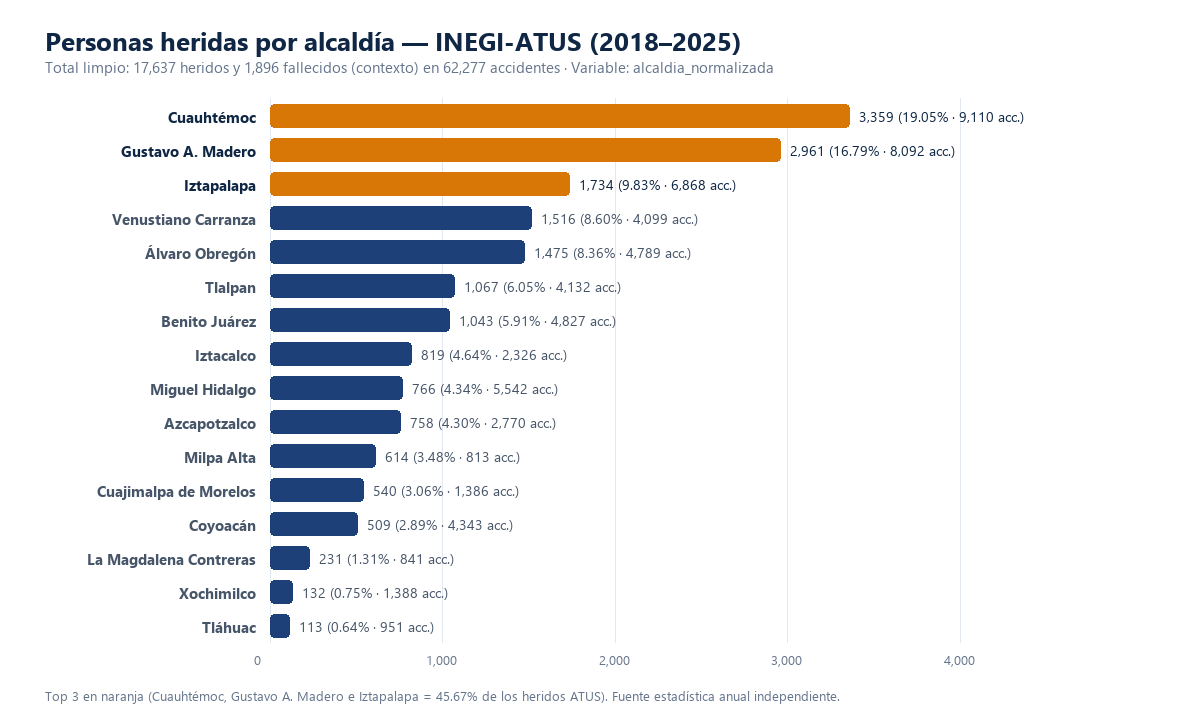

In [4]:
atus_work = atus_limpio.copy()
atus_work["_her_num"] = pd.to_numeric(atus_work[COL_HER], errors="coerce").fillna(0).astype(int)
atus_work["_fal_num"] = pd.to_numeric(atus_work[COL_FAL], errors="coerce").fillna(0).astype(int)
atus_work["_alc"] = atus_work[COL_ALC].astype("string").str.strip()

por_alcaldia_atus = (
    atus_work.groupby("_alc")
    .agg(
        accidentes=("_her_num", "size"),
        heridos=("_her_num", "sum"),
        fallecidos=("_fal_num", "sum"),
    )
    .sort_values("heridos", ascending=False)
    .reset_index()
    .rename(columns={"_alc": "alcaldia"})
)
total_her_atus = int(por_alcaldia_atus["heridos"].sum())
total_acc_atus = int(por_alcaldia_atus["accidentes"].sum())
total_fal_atus = int(por_alcaldia_atus["fallecidos"].sum())
por_alcaldia_atus["porcentaje_heridos"] = (por_alcaldia_atus["heridos"] / total_her_atus * 100).round(2)
por_alcaldia_atus["porcentaje_accidentes"] = (por_alcaldia_atus["accidentes"] / total_acc_atus * 100).round(2)
assert len(por_alcaldia_atus) == 16

display(por_alcaldia_atus)
guardar_resumen(por_alcaldia_atus, "heridos_por_alcaldia_inegi.csv.gz")
top3_her_atus = int(por_alcaldia_atus.head(3)["heridos"].sum())
print(f"Total limpio INEGI-ATUS (16 alcaldías): {total_her_atus:,} heridos y {total_fal_atus:,} fallecidos en {total_acc_atus:,} accidentes.")
print(f"Top 3 concentran: {top3_her_atus:,} heridos ({top3_her_atus / total_her_atus * 100:.2f}%).")

if plt is not None and len(por_alcaldia_atus):
    ax = por_alcaldia_atus.sort_values("heridos").plot.barh(
        x="alcaldia", y="heridos", legend=False, figsize=(10, 7)
    )
    ax.set_title("Personas heridas por alcaldía — INEGI-ATUS (2018–2025)")
    ax.set_xlabel("Personas heridas")
    ax.set_ylabel("Alcaldía")
    plt.tight_layout()
    plt.savefig(RUN / "grafica_01_alcaldias_inegi.png", dpi=160)
    plt.show()
elif PilImage is not None and len(por_alcaldia_atus):
    graficar_barh_alcaldia_inegi_pil(por_alcaldia_atus, total_her_atus, total_acc_atus, total_fal_atus)

## 5. Medida 2 — Distribución por franja horaria (`_franja_horaria` / `ID_HORA`)
- **Pregunta analítica:** ¿En qué franjas de 6 horas se concentran las personas heridas y en cuáles ocurren los siniestros de mayor letalidad en INEGI-ATUS?
- **Variables y medida:** `_total_heridos_validado`, `_total_fallecidos_validado` y accidentes por `_franja_horaria` · **Suma absoluta, `%` y tasa descriptiva de fallecidos por cada 100 accidentes**.
- **Justificación:** INEGI-ATUS presenta cobertura horaria del `100%` (`0` faltantes en `ID_HORA`), lo que permite distinguir la hora pico de heridos (`Tarde`) del pico relativo de letalidad (`Madrugada`).

,franja,accidentes,heridos,fallecidos,porcentaje_heridos,porcentaje_fallecidos,fallecidos_por_100_acc
0,Madrugada,10078,3216,490,18.23,25.84,4.86
1,Mañana,17930,4828,533,27.37,28.11,2.97
2,Tarde,18174,4998,440,28.34,23.21,2.42
3,Noche,16095,4595,433,26.05,22.84,2.69


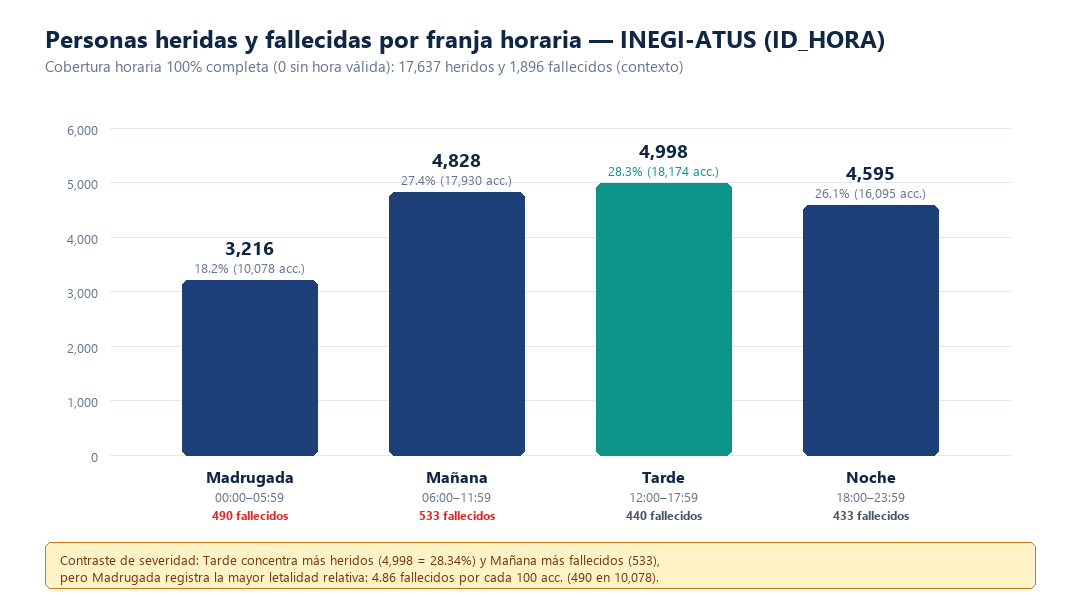

In [5]:
orden_franjas = ["Madrugada", "Mañana", "Tarde", "Noche"]
atus_work["_fr"] = pd.Categorical(atus_work[COL_FRANJA].astype("string").str.strip(), categories=orden_franjas, ordered=True)
assert int(atus_work["_fr"].isna().sum()) == 0, "Se detectaron franjas horarias nulas inesperadas en ATUS"

por_franja_atus = (
    atus_work.groupby("_fr", observed=False)
    .agg(
        accidentes=("_her_num", "size"),
        heridos=("_her_num", "sum"),
        fallecidos=("_fal_num", "sum"),
    )
    .reset_index()
    .rename(columns={"_fr": "franja"})
)
por_franja_atus["porcentaje_heridos"] = (por_franja_atus["heridos"] / total_her_atus * 100).round(2)
por_franja_atus["porcentaje_fallecidos"] = (por_franja_atus["fallecidos"] / total_fal_atus * 100).round(2)
por_franja_atus["fallecidos_por_100_acc"] = (por_franja_atus["fallecidos"] / por_franja_atus["accidentes"] * 100).round(2)

display(por_franja_atus)
guardar_resumen(por_franja_atus, "heridos_por_franja_inegi.csv.gz")

if plt is not None and len(por_franja_atus):
    por_franja_atus.plot.bar(
        x="franja", y="heridos", legend=False,
        title="Personas heridas por franja horaria — INEGI-ATUS (2018–2025)", rot=0
    )
    plt.ylabel("Personas heridas")
    plt.xlabel("Franja horaria")
    plt.tight_layout()
    plt.savefig(RUN / "grafica_02_franjas_inegi.png", dpi=160)
    plt.show()
elif PilImage is not None and len(por_franja_atus):
    graficar_bar_franjas_inegi_pil(por_franja_atus, total_her_atus, total_fal_atus)

## 6. Medida 3 — Tendencia central y dispersión de heridos por accidente y clase (`CLASACC`)
- **Pregunta analítica:** ¿Cuántas personas heridas se registran típicamente por accidente administrativo en ATUS y qué peso tienen los siniestros de *Sólo daños*, *No fatal* y *Fatal*?
- **Variables y medida:** `_total_heridos_validado` por accidente (`N = 62,277`) y agrupación por `CLASACC` · **Media, mediana, moda, desviación estándar, cuartiles (`Q1, Q2, Q3`) y mínimo/máximo**.

,medida,valor
0,Media,0.2832
1,Mediana (Q2),0.0
2,Moda(s),0
3,Desviación estándar,0.6803
4,Q1 (25%),0.0
5,Q3 (75%),0.0
6,Mínimo,0.0
7,Máximo,43.0
8,Accidentes con 0 heridos,48071
9,Accidentes con >=1 herido,14206


,CLASACC,accidentes,heridos,fallecidos,porcentaje_accidentes
0,Sólo daños,46503,0,0,74.67
1,No fatal,13961,17264,0,22.42
2,Fatal,1813,373,1896,2.91


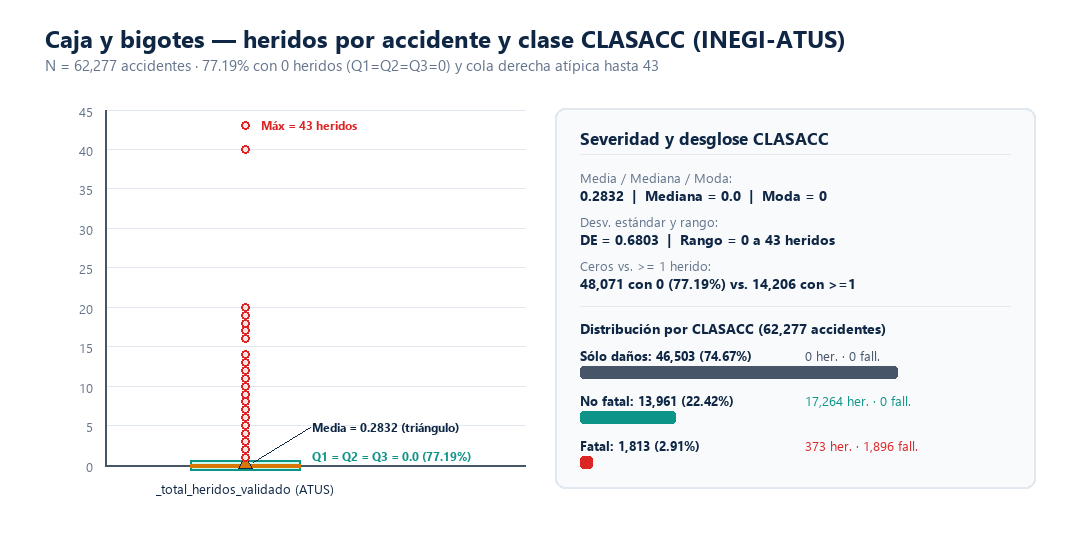

In [6]:
serie_her = atus_work["_her_num"]
modas_her = serie_her.mode().tolist()
est_heridos = pd.DataFrame([
    {"medida": "Media", "valor": round(float(serie_her.mean()), 4)},
    {"medida": "Mediana (Q2)", "valor": float(serie_her.median())},
    {"medida": "Moda(s)", "valor": ", ".join(map(str, modas_her))},
    {"medida": "Desviación estándar", "valor": round(float(serie_her.std()), 4)},
    {"medida": "Q1 (25%)", "valor": float(serie_her.quantile(.25))},
    {"medida": "Q3 (75%)", "valor": float(serie_her.quantile(.75))},
    {"medida": "Mínimo", "valor": float(serie_her.min())},
    {"medida": "Máximo", "valor": float(serie_her.max())},
    {"medida": "Accidentes con 0 heridos", "valor": int((serie_her == 0).sum())},
    {"medida": "Accidentes con >=1 herido", "valor": int((serie_her > 0).sum())},
    {"medida": "N válido (accidentes)", "valor": int(len(serie_her))},
])
display(est_heridos)
guardar_resumen(est_heridos, "estadisticas_heridos_inegi.csv.gz")

por_clasacc = (
    atus_work.groupby(COL_CLAS)
    .agg(
        accidentes=("_her_num", "size"),
        heridos=("_her_num", "sum"),
        fallecidos=("_fal_num", "sum"),
    )
    .sort_values("accidentes", ascending=False)
    .reset_index()
    .rename(columns={COL_CLAS: "CLASACC"})
)
por_clasacc["porcentaje_accidentes"] = (por_clasacc["accidentes"] / total_acc_atus * 100).round(2)
display(por_clasacc)
guardar_resumen(por_clasacc, "resumen_clasacc_inegi.csv.gz")

if plt is not None:
    plt.figure(figsize=(9, 4))
    plt.boxplot(serie_her, vert=True, showmeans=True)
    plt.title("Caja y bigotes — personas heridas por accidente (INEGI-ATUS)")
    plt.ylabel("Personas heridas")
    plt.grid(axis="y", alpha=.25)
    plt.tight_layout()
    plt.savefig(RUN / "grafica_03_boxplot_heridos_inegi.png", dpi=160)
    plt.show()
elif PilImage is not None:
    graficar_boxplot_heridos_inegi_pil(serie_her, por_clasacc)

## 7. Medida 4 — Comparativa pre/post deduplicación (`INEGI-R01`), evolución anual y edad del conductor (`ID_EDAD`)
- **Pregunta analítica:** ¿Cómo cambia el universo ATUS al retirar `145` copias exactas sobre las 46 columnas (`INEGI-R01`), cuál es la tendencia anual `2018–2025` y qué edad presentan los conductores identificados?
- **Variables y medidas:** reconstrucción pre-deduplicación (`limpio + duplicados_exactos + pendientes`), conteos anuales por `ANIO` y medidas descriptivas de `ID_EDAD` conocida (`1–98`) separando `0 = Se fugó` (`RG-03`) y `99 = No especificado`.

Top alcaldías en 145 duplicados exactos: {'Cuauhtémoc': np.int64(75), 'Gustavo A. Madero': np.int64(12), 'Iztapalapa': np.int64(12)}
Top años en 145 duplicados exactos: {'2024': np.int64(77), '2023': np.int64(22), '2021': np.int64(12)}


,conjunto,accidentes,heridos,fallecidos
0,Delimitado pre INEGI-R01 (CDMX 2018–2025),62424,17652,1899
1,Limpio post INEGI-R01/R02 (sin 145 dups ni 2 pend.),62277,17637,1896
2,Duplicados exactos retirados (46 cols),145,15,3


,ANIO,accidentes,heridos,fallecidos
0,2018,11647,2636,240
1,2019,10668,2867,226
2,2020,6546,1603,150
3,2021,6731,1846,168
4,2022,7587,2124,255
5,2023,7252,2427,298
6,2024,6578,2232,290
7,2025,5268,1902,269


,medida,valor
0,N conductores con edad conocida (1–98),48666
1,Media edad conductor (1–98),38.5008
2,Mediana (Q2),37.0
3,Moda,30
4,Desviación estándar,12.9277
5,Q1 (25%),28.0
6,Q3 (75%),47.0
7,Mínimo / Máximo (1–98),13 – 98
8,ID_EDAD = 0 (SEXO='Se fugó'),12948
9,Verificación coincidencia 0 == 'Se fugó',12948


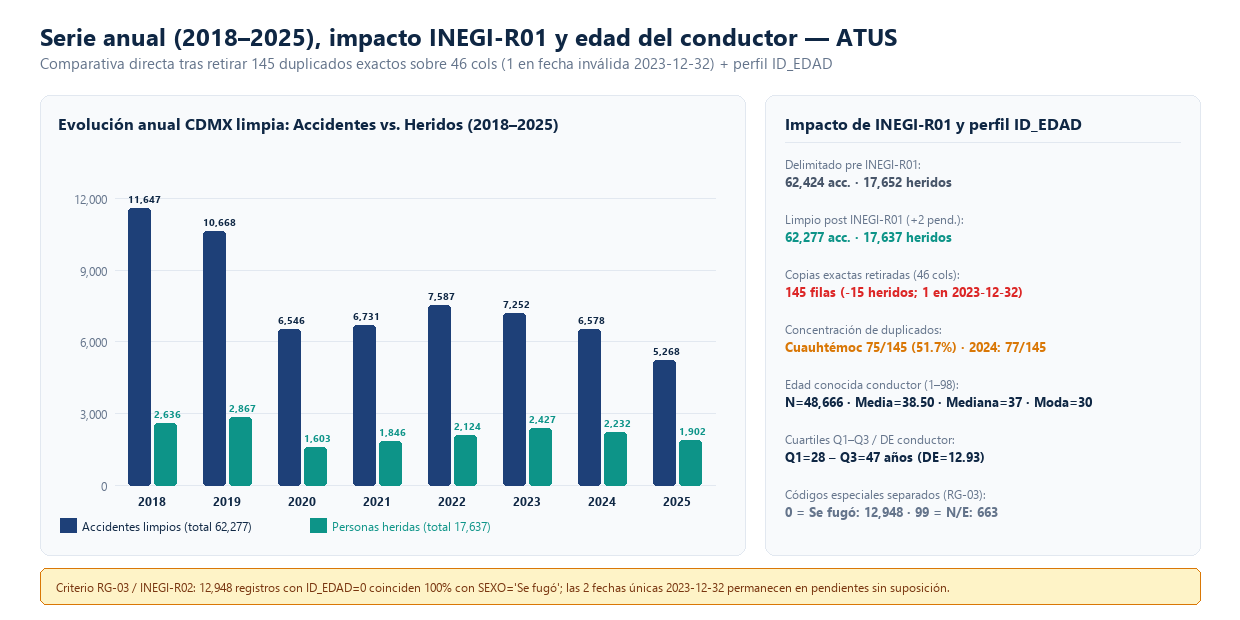

In [7]:
HERIDOS_ATUS_COLS = ["CONDHERIDO", "PASAHERIDO", "PEATHERIDO", "CICLHERIDO", "OTROHERIDO", "NEHERIDO"]
MUERTOS_ATUS_COLS = ["CONDMUERTO", "PASAMUERTO", "PEATMUERTO", "CICLMUERTO", "OTROMUERTO", "NEMUERTO"]

def sumar_victimas(df, cols):
    if not len(df):
        return 0
    return int(sum(pd.to_numeric(df[c], errors="coerce").fillna(0).clip(lower=0).sum() for c in cols if c in df.columns))

dup_her = sumar_victimas(atus_dups, HERIDOS_ATUS_COLS)
dup_fal = sumar_victimas(atus_dups, MUERTOS_ATUS_COLS)
pend_her = sumar_victimas(atus_pend, HERIDOS_ATUS_COLS)
pend_fal = sumar_victimas(atus_pend, MUERTOS_ATUS_COLS)

comparativa_r01 = pd.DataFrame([
    {
        "conjunto": "Delimitado pre INEGI-R01 (CDMX 2018–2025)",
        "accidentes": total_acc_atus + len(atus_dups) + len(atus_pend),
        "heridos": total_her_atus + dup_her + pend_her,
        "fallecidos": total_fal_atus + dup_fal + pend_fal,
    },
    {
        "conjunto": "Limpio post INEGI-R01/R02 (sin 145 dups ni 2 pend.)",
        "accidentes": total_acc_atus,
        "heridos": total_her_atus,
        "fallecidos": total_fal_atus,
    },
    {
        "conjunto": "Duplicados exactos retirados (46 cols)",
        "accidentes": len(atus_dups),
        "heridos": dup_her,
        "fallecidos": dup_fal,
    },
])
display(comparativa_r01)
guardar_resumen(comparativa_r01, "comparativa_dedup_inegi_r01.csv.gz")
if len(atus_dups):
    print("Top alcaldías en 145 duplicados exactos:", dict(atus_dups["alcaldia_normalizada"].value_counts().head(3)))
    print("Top años en 145 duplicados exactos:", dict(atus_dups["ANIO"].value_counts().head(3)))

# Evolución anual 2018-2025
evolucion_anual = (
    atus_work.groupby(COL_ANIO)
    .agg(
        accidentes=("_her_num", "size"),
        heridos=("_her_num", "sum"),
        fallecidos=("_fal_num", "sum"),
    )
    .sort_index()
    .reset_index()
    .rename(columns={COL_ANIO: "ANIO"})
)
display(evolucion_anual)
guardar_resumen(evolucion_anual, "evolucion_anual_inegi.csv.gz")

# Edad del conductor (separando 0 = Se fugó y 99 = N/E)
ed_num = pd.to_numeric(atus_work[COL_EDAD], errors="coerce")
n_fugo = int((ed_num == 0).sum())
n_99 = int((ed_num == 99).sum())
fugo_check = int(((ed_num == 0) & atus_work[COL_SEXO].astype("string").str.strip().eq("Se fugó")).sum()) if COL_SEXO else n_fugo
ed_ok = ed_num[ed_num.between(1, 98)]

ed_summary_df = pd.DataFrame([
    {"medida": "N conductores con edad conocida (1–98)", "valor": int(len(ed_ok))},
    {"medida": "Media edad conductor (1–98)", "valor": round(float(ed_ok.mean()), 4)},
    {"medida": "Mediana (Q2)", "valor": float(ed_ok.median())},
    {"medida": "Moda", "valor": int(ed_ok.mode().iloc[0])},
    {"medida": "Desviación estándar", "valor": round(float(ed_ok.std()), 4)},
    {"medida": "Q1 (25%)", "valor": float(ed_ok.quantile(.25))},
    {"medida": "Q3 (75%)", "valor": float(ed_ok.quantile(.75))},
    {"medida": "Mínimo / Máximo (1–98)", "valor": f"{int(ed_ok.min())} – {int(ed_ok.max())}"},
    {"medida": "ID_EDAD = 0 (SEXO='Se fugó')", "valor": n_fugo},
    {"medida": "Verificación coincidencia 0 == 'Se fugó'", "valor": fugo_check},
    {"medida": "ID_EDAD = 99 (No especificado)", "valor": n_99},
])
display(ed_summary_df)
guardar_resumen(ed_summary_df, "estadisticas_edad_conductor_inegi.csv.gz")

ed_stats_dict = {
    "n_ok": int(len(ed_ok)),
    "mean": float(ed_ok.mean()),
    "median": float(ed_ok.median()),
    "mode": float(ed_ok.mode().iloc[0]),
    "std": float(ed_ok.std()),
    "q1": float(ed_ok.quantile(.25)),
    "q3": float(ed_ok.quantile(.75)),
    "n_fugo": n_fugo,
    "n_99": n_99,
}

if plt is not None:
    ax = evolucion_anual.plot.bar(x="ANIO", y=["accidentes", "heridos"], figsize=(10, 4.5), title="Evolución anual limpia INEGI-ATUS (2018–2025)", rot=0)
    plt.tight_layout()
    plt.savefig(RUN / "grafica_04_comparativa_r01_y_anual_inegi.png", dpi=160)
    plt.show()
elif PilImage is not None:
    graficar_comparativa_r01_y_anual_inegi_pil(evolucion_anual, comparativa_r01, ed_stats_dict)

## 8. Resumen de ejecución, registro en bitácora y limitaciones
Cerramos el análisis exportando `resumen_ejecucion_analisis_inegi.csv.gz` y registrando automáticamente la corrida estadística en `bitacora/bitacora.csv` (`idn_avance03_guia.pdf`, sección 3.6).

In [8]:
resumen_ejecucion = pd.DataFrame([
    {"elemento": "Origen de datos INEGI-ATUS", "valor": ORIGEN_ATUS},
    {"elemento": "Ejecución INEGI-ATUS utilizada", "valor": str(ATUS_RUN)},
    {"elemento": "Accidentes limpios (2018–2025)", "valor": total_acc_atus},
    {"elemento": "Duplicados exactos retirados (46 cols)", "valor": len(atus_dups)},
    {"elemento": "Pendientes calendario (2023-12-32)", "valor": len(atus_pend)},
    {"elemento": "Total personas heridas (_total_heridos_validado)", "valor": total_her_atus},
    {"elemento": "Total personas fallecidas (contexto)", "valor": total_fal_atus},
    {"elemento": "N edades válidas conductor (1–98)", "valor": int(len(ed_ok))},
    {"elemento": "Carpeta de resultados análisis INEGI-ATUS", "valor": str(RUN)},
])
display(resumen_ejecucion)
guardar_resumen(resumen_ejecucion, "resumen_ejecucion_analisis_inegi.csv.gz")

fila_bit = pd.DataFrame([{
    "fecha": datetime.now(TZ).isoformat(timespec="seconds"),
    "fuente": "Analisis_INEGI_ATUS",
    "run_id": RUN_ID,
    "responsable": RESPONSABLE_EQUIPO,
    "archivo": str(ATUS_RUN.name),
    "paso": "Cálculo estadístico descriptivo INEGI-ATUS (4 bloques)",
    "regla": "Nota10/Guia3.5/INEGI-R01/R02",
    "filas_antes": len(atus_limpio),
    "filas_despues": len(atus_limpio),
    "resultado": "Correcto; 4 bloques INEGI-ATUS calculados y exportados",
    "detalle": (
        f"Accidentes={total_acc_atus:,}; Heridos={total_her_atus:,}; Fallecidos={total_fal_atus:,}; "
        f"Dups_retirados={len(atus_dups)}; Edades_1_98={len(ed_ok):,}; Salida={RUN}"
    ),
    "observaciones": "Resultados en data/processed/Analisis_INEGI_ATUS/<RUN_ID>/; sin unión ni suma con SSC ni C5.",
    "version_proceso": VERSION_PROCESO,
}])
BITACORA_GLOBAL_PATH.parent.mkdir(parents=True, exist_ok=True)
if BITACORA_GLOBAL_PATH.is_file():
    prev = pd.read_csv(BITACORA_GLOBAL_PATH, dtype=str, encoding="utf-8-sig")
    if {"fuente", "run_id"}.issubset(prev.columns):
        prev = prev.loc[~(prev["fuente"].eq("Analisis_INEGI_ATUS") & prev["run_id"].eq(RUN_ID))]
    pd.concat([prev, fila_bit.astype(str)], ignore_index=True).to_csv(BITACORA_GLOBAL_PATH, index=False, encoding="utf-8-sig")
else:
    fila_bit.to_csv(BITACORA_GLOBAL_PATH, index=False, encoding="utf-8-sig")
fila_bit.to_csv(RUN_LOG / "bitacora_analisis_inegi_atus.csv", index=False, encoding="utf-8-sig")

print("Análisis estadístico INEGI-ATUS terminado. Resultados en:", RUN)
print("Bitácora global actualizada en:", BITACORA_GLOBAL_PATH)

Análisis estadístico INEGI-ATUS terminado. Resultados en: C:\Users\angel\Downloads\CARPETA_DATOS\data\processed\Analisis_INEGI_ATUS\20261109_132940
Bitácora global actualizada en: C:\Users\angel\Downloads\CARPETA_DATOS\bitacora\bitacora.csv


,elemento,valor
0,Origen de datos INEGI-ATUS,Avance03 - ETL INEGI-ATUS (limpios .csv.gz)
1,Ejecución INEGI-ATUS utilizada,C:\Users\angel\Downloads\CARPETA_DATOS\data\processed\INEGI_ATUS\20261109_043449
2,Accidentes limpios (2018–2025),62277
3,Duplicados exactos retirados (46 cols),145
4,Pendientes calendario (2023-12-32),2
5,Total personas heridas (_total_heridos_validado),17637
6,Total personas fallecidas (contexto),1896
7,N edades válidas conductor (1–98),48666
8,Carpeta de resultados análisis INEGI-ATUS,C:\Users\angel\Downloads\CARPETA_DATOS\data\processed\Analisis_INEGI_ATUS\20261109_132940
